# Does agreement among sector ETF peers predict price catch-up?


## 1. Hypothesis Pitch 

When a sector or industry ETF fails to move while its historically related sector or industry ETF peers move together in one direction, it tends to catch up over the next five trading sessions. I select its five peers from the other ETFs using the highest correlations of daily returns over the previous 252 trading observations, ending before the signal day. Specifically, I think the catch-up is stronger when the peer move reflects agreement across several peers than when the same average move comes from one exceptional peer. I measure agreement as the standard deviation of the five peers' returns on the signal day, divided by the peers' average daily volatility over the previous 21 sessions. The lower it is, the more alike the peers move, relative to how much they usually move. I assume that T's five-day catch-up should be larger when that standard deviation is close to 0, and smaller when it is high. 

### Example

Both rows have the same +2% average peer return, and the standard deviation is 0% in scenario 1 and about 4.5% in scenario 2. I predict the target T rises, and it rises more where the standard deviation is 0%. 

| Metric | Scenario 1: Broad Agreement | Scenario 2: One Exceptional Peer |
|---|---:|---:|
| Peer A's return today | +2% | +10% |
| Peer B's return today | +2% | 0% |
| Peer C's return today | +2% | 0% |
| Peer D's return today | +2% | 0% |
| Peer E's return today | +2% | 0% |
| **Average of the 5 peers** | **+2%** | **+2%** |
| **Spread of the 5 peers (standard deviation)** | **0%** | **4.5%** |
| Target sector or industry ETF T's return today | +0.2% | +0.2% |
| **T's return over the next 5 days (my prediction)** | **Large catch-up, e.g. +1.4%** | **Small catch-up, e.g. +0.3%** |

### Why I think it might be true

When several related sector or industry ETFs rise by similar amounts, this may reflect shared economic information. My proposed mechanism is that investors adjust exposure to some sectors before others, temporarily leaving target ETF T behind. However, different sector sensitivities could also explain the divergence, so a lag is not automatically evidence of delayed reaction. 

When the same average peer return comes mainly from one exceptional ETF, the rise may instead reflect information specific to that sector. There is then less reason for T to follow. This is why I expect stronger catch-up when the spread of peer returns is lower. I will measure each trade's return relative to its five peers and compare the average for Low and High dispersion signals, checking that both groups had similar peer moves. The test uses upward peer moves only (long trades), so market drift affects both groups in the same way.


### What would prove me wrong

I would abandon the hypothesis if, across the out-of-sample period, trades after low-dispersion peer moves do not catch up more over five sessions, measured relative to their peers, than trades after high-dispersion peer moves.

I would also abandon its use as a trading strategy if the catch up happens before I can enter at the next trading session’s open, or if transaction costs remove the benefit. If the results are too uncertain to draw a clear conclusion, I would report the evidence as inconclusive.


The target and its peers are drawn from a fixed sample of 21 sector and industry SPDR ETFs, all launched before the test begins. This tests sector-level catch-up, rather than individual-company catch-up. The funds share market exposure, so signals across funds and overlapping five-session periods must not be treated as independent evidence.


# Data Pipeline

### 1. Data retrieval

The fixed sample contains the original nine sector ETFs and twelve industry ETFs: KBE, KCE, KIE, KRE, XBI, XHB, XME, XOP, XRT, XSD, XPH and XES. All existed before 2012. Their launch dates, taken from the official State Street fact sheets, are listed in the code, which checks that every fund existed before the first correlation lookback.

This is a research sample, not a reconstruction of every ETF available historically. Selecting currently available funds leaves a potential survivorship/selection bias. Sector and industry funds also overlap in holdings. We do not remove a fund because its test performance is poor or its download fails.

Download December 2009 through December 2025: 2010 provides the first correlation lookback, 2011 provides the first calibration year, and trading tests cover every full year from 2012 through 2025. Yahoo excludes `date_end`.

By default the notebook reruns from the saved snapshot `data/raw_etf_market_data.parquet`, so it needs no internet and reproduces the reported results exactly. Yahoo revises adjusted prices after every distribution, so a fresh download can differ slightly. Set `USE_SNAPSHOT = False` to download again and replace the snapshot.


In [11]:
import pandas as pd
import yfinance as yf
from pathlib import Path

# A fixed sample of sector and industry ETFs, all launched before 2012.
ETF_UNIVERSE = {
    "XLB": "Materials", "XLE": "Energy", "XLF": "Financials",
    "XLI": "Industrials", "XLK": "Technology", "XLP": "Consumer Staples",
    "XLU": "Utilities", "XLV": "Health Care", "XLY": "Consumer Discretionary",
    "KBE": "Banks", "KCE": "Capital Markets", "KIE": "Insurance",
    "KRE": "Regional Banking", "XBI": "Biotechnology", "XHB": "Homebuilders",
    "XME": "Metals & Mining", "XOP": "Oil & Gas Exploration & Production",
    "XRT": "Retail", "XSD": "Semiconductors", "XPH": "Pharmaceuticals",
    "XES": "Oil & Gas Equipment & Services",
}

ETF_INCEPTION = {
    "XLB": "1998-12-16", "XLE": "1998-12-16", "XLF": "1998-12-16",
    "XLI": "1998-12-16", "XLK": "1998-12-16", "XLP": "1998-12-16",
    "XLU": "1998-12-16", "XLV": "1998-12-16", "XLY": "1998-12-16",
    "KBE": "2005-11-08", "KCE": "2005-11-08", "KIE": "2005-11-08",
    "KRE": "2006-06-19", "XBI": "2006-01-31", "XHB": "2006-01-31",
    "XME": "2006-06-19", "XOP": "2006-06-19", "XRT": "2006-06-19",
    "XSD": "2006-01-31", "XPH": "2006-06-19", "XES": "2006-06-19",
}
TICKERS = list(ETF_UNIVERSE)


def fetch_ticker(ticker: str, date_start: str, date_end: str) -> pd.DataFrame | None:
    """Download one ETF. Return None if it has no usable closing prices."""
    try:
        data = yf.download(
            ticker,
            start=date_start,
            end=date_end, 
            interval="1d",
            auto_adjust=True,  # Adjust OHLC for splits and distributions.
            progress=False,
            threads=False,
            multi_level_index=True,  # (field, ticker) 
            timeout=15,
        )

        if data is None or data.empty:
            print(f"Failed: {ticker} returned no data.")
            return None

        if ("Close", ticker) not in data.columns:
            print(f"Failed: {ticker} has no Close column.")
            return None

        if data[("Close", ticker)].isna().all():
            print(f"Failed: {ticker} has no closing prices.")
            return None

        print(f"Fetched {ticker}: {len(data)} daily bars")
        return data

    except Exception as error:
        print(f"Failed: {ticker}: {error}")
        return None


def fetch_all_data(date_start: str, date_end: str) -> tuple[pd.DataFrame | None, list[str]]:
    """Return the combined successful downloads and the list of failed tickers."""
    start = pd.to_datetime(date_start, format="%Y-%m-%d", errors="raise")
    end = pd.to_datetime(date_end, format="%Y-%m-%d", errors="raise")
    if pd.isna(start) or pd.isna(end) or start >= end:
        raise ValueError("date_start must be earlier than date_end. Use YYYY-MM-DD.")

    tickers = TICKERS
    print(f"Selected {len(tickers)} ETFs: {tickers}")

    successful_downloads = []
    failed_tickers = []

    # Finish each ticker before starting the next one
    for ticker in tickers:
        data = fetch_ticker(ticker, date_start, date_end)

        if data is None:
            failed_tickers.append(ticker)
        else:
            successful_downloads.append(data)

    print(f"Successful downloads: {len(successful_downloads)}")
    print(f"{len(failed_tickers)} tickers failed: {failed_tickers}")

    if not successful_downloads:
        return None, failed_tickers

    # Combine only successful downloads, with each ticker's columns side by side.
    combined = pd.concat(successful_downloads, axis=1).sort_index()
    return combined, failed_tickers



backtest_start = "2012-01-01"  # first day the strategy can trade
date_end = "2026-01-01"        

# The first trade in 2012 needs two years of history before it:
#   2011: gives the Low/High cutoffs for 2012 (they come from the previous year).
#   2010: gives the peers for 2011 (they come from the previous 252 trading days).
# One extra month (December 2009) makes sure a full 252 daily returns exist before 2011,
# because the very first day has no return. So we download from 2009-12-01.
date_start = (
    pd.to_datetime(backtest_start, format="%Y-%m-%d", errors="raise")
    - pd.DateOffset(years=2, months=1)
).strftime("%Y-%m-%d")

# Every ETF must already exist on the first download day. Otherwise it would have
# missing history and quietly join the sample partway through.
if pd.to_datetime(list(ETF_INCEPTION.values())).max() >= pd.Timestamp(date_start):
    raise ValueError("A selected ETF did not exist before the required lookback.")

# Rerun from the saved parquet snapshot 
USE_SNAPSHOT = True
SNAPSHOT = Path("data/raw_etf_market_data.parquet")

if USE_SNAPSHOT and SNAPSHOT.exists():
    print(f"Loading saved snapshot: {SNAPSHOT}")
    data = pd.read_parquet(SNAPSHOT)
    if set(data.columns.get_level_values(1)) != set(TICKERS):
        raise ValueError("The snapshot does not contain the fixed ETF universe; set USE_SNAPSHOT = False.")
else:
    print(f"Price download: {date_start} to {date_end}")
    data, failed_tickers = fetch_all_data(date_start=date_start, date_end=date_end)
    if data is None or failed_tickers:
        raise ValueError(f"Retry failed downloads before changing the fixed universe: {failed_tickers}")
    data.to_csv("data/raw_etf_market_data.csv")
    data.to_parquet(SNAPSHOT)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
display(data.head(10))


Loading saved snapshot: data/raw_etf_market_data.parquet


Price,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume,Close,High,Low,Open,Volume
Ticker,XLB,XLB,XLB,XLB,XLB,XLE,XLE,XLE,XLE,XLE,XLF,XLF,XLF,XLF,XLF,XLI,XLI,XLI,XLI,XLI,XLK,XLK,XLK,XLK,XLK,XLP,XLP,XLP,XLP,XLP,XLU,XLU,XLU,XLU,XLU,XLV,XLV,XLV,XLV,XLV,XLY,XLY,XLY,XLY,XLY,KBE,KBE,KBE,KBE,KBE,KCE,KCE,KCE,KCE,KCE,KIE,KIE,KIE,KIE,KIE,KRE,KRE,KRE,KRE,KRE,XBI,XBI,XBI,XBI,XBI,XHB,XHB,XHB,XHB,XHB,XME,XME,XME,XME,XME,XOP,XOP,XOP,XOP,XOP,XRT,XRT,XRT,XRT,XRT,XSD,XSD,XSD,XSD,XSD,XPH,XPH,XPH,XPH,XPH,XES,XES,XES,XES,XES
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12-01,11.541335,11.604041,11.475145,11.506498,22712400,16.593653,16.729123,16.559065,16.596536,31061400,8.834862,8.913153,8.786682,8.889063,106757244,20.418230,20.491257,20.235664,20.352507,8460800,8.854451,8.874484,8.778327,8.782333,17054200,17.163736,17.170058,16.961438,17.068909,5351500,8.450596,8.453383,8.336323,8.355833,21079200,23.365931,23.365931,23.021654,23.021654,5944900,11.812613,11.865440,11.727280,11.731344,14076800,15.491693,15.681215,15.372364,15.632080,5501500,25.005470,25.177732,24.853879,24.909004,71000,8.513877,8.573138,8.471901,8.538569,2217300,14.503407,14.676067,14.441250,14.579378,2603500,16.363039,16.414366,16.067922,16.067922,416700,12.579096,12.699387,12.381473,12.424435,5859600,40.016651,40.619433,39.799649,39.888058,3555900,119.844711,120.304349,118.833487,119.323775,432500,13.971189,14.078385,13.725036,13.812381,24177400,19.358728,19.399801,18.938879,18.938879,177800,14.009018,14.009018,13.874063,13.877813,16800,229.832001,231.970743,229.502969,230.161032,9630
2009-12-02,11.652813,11.705067,11.537852,11.548304,18306800,16.495649,16.674354,16.420709,16.593649,31288600,8.828839,8.870996,8.780661,8.816795,76497910,20.359808,20.549677,20.286783,20.418229,6255100,8.842433,8.922564,8.826407,8.854453,10424400,17.144762,17.189015,17.068900,17.113152,4973400,8.564870,8.564870,8.453385,8.478469,26181000,23.313541,23.418322,23.201277,23.328510,4983300,11.849180,11.918260,11.763847,11.800419,10860000,15.561891,15.639104,15.442562,15.463620,11041400,24.957232,25.163945,24.902107,24.998573,37300,8.573142,8.610181,8.474373,8.494128,1517100,14.717495,14.855623,14.524117,14.634619,2499200,16.468904,16.587595,16.350216,16.427203,826500,12.622052,12.759529,12.570499,12.579091,5249600,40.788204,41.117725,40.169348,40.225608,4901300,118.741516,120.580090,118.312516,120.120452,395700,13.995008,14.189549,13.943394,13.967216,19965800,19.623413,19.833338,19.454561,19.472814,175800,14.046509,14.117734,13.967784,14.039011,26400,227.940094,230.901428,226.870710,228.515893,13830
2009-12-03,11.464698,11.708554,11.454247,11.656298,28935400,16.230478,16.536006,16.216066,16.489889,39432200,8.648164,8.997462,8.630096,8.901105,205411431,20.264877,20.549681,20.221062,20.425535,6783000,8.846438,8.922563,8.826406,8.882497,12896600,17.012012,17.170058,16.986726,17.170058,7580100,8.592742,8.654059,8.528638,8.592742,19928400,23.201277,23.440774,23.148887,23.380899,7722800,11.767913,11.930454,11.743532,11.902009,14958000,15.091591,15.856700,15.056495,15.681216,21082600,24.633385,25.191513,24.578260,25.157058,63200,8.383010,8.728701,8.350910,8.592894,3937500,14.351468,15.007574,14.351468,14.834914,3898800,16.330959,16.667780,16.327753,16.449648,272100,12.364284,12.690790,12.364284,12.630644,3004800,39.880005,41.013233,39.767486,40.772122,6069300,116.994904,119.538265,116.811041,118.557690,637400,13.756800,14.038685,13.725037,13.867965,38710800,19.

### 2. Data Cleaning

In [12]:
# Work on a copy, so the original data stays unchanged.
if not isinstance(data, pd.DataFrame):
    raise ValueError("data must be a pandas DataFrame.")
if data.empty:
    raise ValueError("There are no rows or columns to clean.")

cleaned = data.copy()
required_fields = ["Open", "High", "Low", "Close"]

# 1. Check the column structure.
if not isinstance(cleaned.columns, pd.MultiIndex):
    raise ValueError("Columns must have two levels: (field, ticker).")

if cleaned.columns.nlevels != 2:
    raise ValueError("Expected exactly two column levels.")

# We aren't using Volume. Ignore it if already absent.
cleaned = cleaned.drop(columns="Volume", level=0, errors="ignore")

# Keep only OHLC fields; unrelated fields do not belong in these price checks.
cleaned = cleaned.loc[:, cleaned.columns.get_level_values(0).isin(required_fields)]
if cleaned.empty:
    raise ValueError("No OHLC price columns were found in column level 0.")

# Check that every ETF has its required fields.
tickers = cleaned.columns.get_level_values(1).unique()

for ticker in tickers:
    for field in required_fields:
        if (field, ticker) not in cleaned.columns:
            raise ValueError(f"{ticker} is missing its {field} column.")

# 2. Convert the index to dates.
# Accept a DatetimeIndex or ISO date strings such as "2020-01-31".
# Reject numeric indexes rather than interpreting them as dates near 1970.
if isinstance(cleaned.index, pd.DatetimeIndex):
    dates = cleaned.index
else:
    if not all(isinstance(value, str) for value in cleaned.index):
        raise ValueError("The index must contain datetimes or YYYY-MM-DD strings.")
    dates = pd.to_datetime(cleaned.index, format="%Y-%m-%d", errors="coerce")
bad_dates = cleaned.index[dates.isna()]

if len(bad_dates) > 0:
    raise ValueError(f"Unreadable or missing dates: {bad_dates.tolist()}")

# These are daily session labels. Preserve the local date when removing a timezone.
if dates.tz is not None:
    dates = dates.tz_localize(None)
if (dates != dates.normalize()).any():
    raise ValueError("Daily price dates must not contain times other than midnight.")

cleaned.index = dates

# 3. Check repeated column labels.
# Compare raw values strictly before conversion; conflicting copies need review.
duplicate_columns = cleaned.columns[cleaned.columns.duplicated()].unique()

for column in duplicate_columns:
    copies = cleaned.loc[:, cleaned.columns == column]
    first = copies.iloc[:, 0]

    for i in range(1, copies.shape[1]):
        if not first.equals(copies.iloc[:, i]):
            raise ValueError(
                f"Conflicting values in repeated column: {column}"
            )

# 4. Check repeated dates.
duplicate_dates = cleaned.index[cleaned.index.duplicated()].unique()

for date in duplicate_dates:
    copies = cleaned.loc[cleaned.index == date]
    first = copies.iloc[0]

    for i in range(1, len(copies)):
        if not first.equals(copies.iloc[i]):
            raise ValueError(
                f"Conflicting values on repeated date: {date}"
            )

# 5. Both duplicate checks passed. Keep one copy of each.
removed_columns = cleaned.columns.duplicated().sum()
removed_rows = cleaned.index.duplicated().sum()

cleaned = cleaned.loc[:, ~cleaned.columns.duplicated(keep="first")]
cleaned = cleaned.loc[~cleaned.index.duplicated(keep="first")]

print("Duplicate columns removed:", removed_columns)
print("Duplicate rows removed:", removed_rows)

# 6. Convert each column to numbers and record failed conversions.
conversion_errors = {}

for column in cleaned.columns:
    original = cleaned[column]
    numeric = pd.to_numeric(original, errors="coerce")

    failed = original.notna() & numeric.isna()

    if failed.any():
        conversion_errors[column] = original[failed]

    cleaned[column] = numeric

print("Conversion errors:", conversion_errors)

# 7. Sort dates from oldest to newest.
cleaned = cleaned.sort_index()

# 8. Clean invalid prices and contradictory OHLC observations.
tol = 1.0001  # 0.01% tolerance for Open/Close versus High/Low

invalid_report = {}
invalid_price_log = {}

for ticker in cleaned.columns.get_level_values(1).unique():
    original = cleaned.xs(ticker, axis=1, level=1)[required_fields].copy()

    # 1. Find zero, negative and infinite prices.
    invalid = (
        (original <= 0)
        | original.isin([float("inf"), float("-inf")])
    ).fillna(False)

    # Replace only those individual cells with NaN.
    prices = original.mask(invalid)

    # 2. Check relationships between the remaining prices.
    # High < Low is always a contradiction. Open/Close allow rounding tolerance.
    # A missing comparison means "not checked", rather than "confirmed valid".
    conflict_checks = pd.DataFrame({
        "High_below_Low": prices["High"] < prices["Low"],
        "Open_above_High": prices["Open"] > prices["High"] * tol,
        "Close_above_High": prices["Close"] > prices["High"] * tol,
        "Open_below_Low": prices["Open"] < prices["Low"] / tol,
        "Close_below_Low": prices["Close"] < prices["Low"] / tol,
    }).fillna(False)
    bad_ohlc = conflict_checks.any(axis=1)

    # We cannot tell which price is wrong, so mark all four missing.
    prices.loc[bad_ohlc, required_fields] = float("nan")

    # 3. Identify cells that became missing during this step.
    removed = original.notna() & prices.isna()

    # Skip tickers where nothing changed.
    if not removed.any().any():
        continue

    # Count removed values separately for each field.
    invalid_report[ticker] = removed.sum().to_dict()
    invalid_report[ticker]["ohlc_conflict_days"] = int(bad_ohlc.sum())

    # Keep the original affected rows for investigation.
    affected = removed.any(axis=1)
    invalid_price_log[ticker] = original.loc[affected].copy()
    invalid_price_log[ticker]["ohlc_conflict"] = bad_ohlc.loc[affected]
    # Keep separate reasons so each removed observation can be explained.
    for field in required_fields:
        reason = f"{field}_nonpositive_or_infinite"
        invalid_price_log[ticker][reason] = invalid.loc[affected, field]
    for reason in conflict_checks.columns:
        invalid_price_log[ticker][reason] = conflict_checks.loc[affected, reason]

    # 4. Write the cleaned prices back.
    for field in required_fields:
        cleaned[(field, ticker)] = prices[field]

invalid_summary = pd.DataFrame.from_dict(invalid_report, orient="index")
invalid_summary = invalid_summary.reindex(columns=required_fields + ["ohlc_conflict_days"])
invalid_summary.index.name = "Ticker"

if not invalid_summary.empty:
    print(invalid_summary.to_string())

# 9. Reassess usability after invalid prices have been removed.
# Close is required for return analysis; keep other partial histories for review.
excluded_tickers = {}

tickers = cleaned.columns.get_level_values(1).unique()

for ticker in tickers:
    prices = cleaned.xs(ticker, axis=1, level=1)[required_fields]

    # Check whether each price column is entirely missing.
    empty_columns = prices.isna().all()

    # Exclude completely empty ETFs, then stocks without usable closing prices.
    if empty_columns.all():
        excluded_tickers[ticker] = "All Open, High, Low and Close values are missing."
        cleaned = cleaned.drop(columns=ticker, level=1)
    elif prices["Close"].isna().all():
        excluded_tickers[ticker] = "No usable Close prices remain after cleaning."
        cleaned = cleaned.drop(columns=ticker, level=1)

# Update the ticker list after removing empty ETFs.
tickers = cleaned.columns.get_level_values(1).unique()

print("Excluded tickers:", excluded_tickers)
if len(tickers) == 0:
    raise ValueError("No tickers with usable Close prices remain after cleaning.")

# 10. Report FINAL missing prices and each field's historical coverage.
# These checks use only dates already present in the table.
missing_report = {}
missing_price_dates = {}
first_price_dates = {}
coverage_rows = []

for ticker in tickers:
    prices = cleaned.xs(ticker, axis=1, level=1)[required_fields]

    # Use the first and last dates with ANY available OHLC price.
    start = prices.first_valid_index()
    end = prices.last_valid_index()

    history = prices.loc[start:end]
    counts = history.isna().sum()

    first_price_dates[ticker] = {}
    missing_price_dates[ticker] = {}

    for field in required_fields:
        # Record when this particular field first becomes available.
        first = prices[field].first_valid_index()
        last = prices[field].last_valid_index()
        first_price_dates[ticker][field] = first

        # Boundary gaps are coverage information, not automatically errors.
        # An absent field has no defined first/last date or boundary gap length.
        leading_missing = None
        trailing_missing = None
        if first is not None:
            leading_missing = int((prices.index < first).sum())
            trailing_missing = int((prices.index > last).sum())

        coverage_rows.append({
            "Ticker": ticker,
            "Field": field,
            "First": first,
            "Last": last,
            "Usable_prices": int(prices[field].notna().sum()),
            "Entirely_missing": first is None,
            "Leading_missing_sessions": leading_missing,
            "Trailing_missing_sessions": trailing_missing,
        })

        # Record the dates where this field is missing.
        dates = history.index[history[field].isna()]

        if len(dates) > 0:
            missing_price_dates[ticker][field] = dates.tolist()

    # Check whether all four fields begin on the same date.
    same_first_date = all(
        date == start
        for date in first_price_dates[ticker].values()
    )

    if counts.sum() > 0:
        missing_report[ticker] = counts.to_dict()
        missing_report[ticker]["same_first_date"] = same_first_date

missing_summary = pd.DataFrame.from_dict(missing_report, orient="index")
missing_summary = missing_summary.reindex(columns=required_fields + ["same_first_date"])
missing_summary.index.name = "Ticker"

coverage_report = pd.DataFrame(coverage_rows, columns=[
    "Ticker", "Field", "First", "Last", "Usable_prices", "Entirely_missing",
    "Leading_missing_sessions", "Trailing_missing_sessions",
])
print("Final coverage by ticker and field:")
print(coverage_report.to_string(index=False))

if not missing_summary.empty:
    print(missing_summary.to_string())

# 11. Report price changes above +20% or below -20%.
# Multiple movements can be flagged on the same ticker-date. Keep the prices.
threshold = 0.20
large_return_rows = []

for ticker in cleaned["Close"].columns:
    open_price = cleaned[("Open", ticker)]
    close_price = cleaned[("Close", ticker)]
    # Previous means the previous row; missing dates are not checked here.
    previous_close = close_price.shift(1)

    changes = {
        "Open -> Close": close_price / open_price - 1,
        "Previous Close -> Open": open_price / previous_close - 1,
        "Previous Close -> Close": close_price.pct_change(fill_method=None),
    }

    for movement, returns in changes.items():
        # Select only returns outside the threshold.
        flagged = returns[returns.abs() > threshold]

        for date, value in flagged.items():
            large_return_rows.append({
                "Ticker": ticker,
                "Date": date,
                "Movement": movement,
                "Previous_Close": previous_close.loc[date],
                "Open": open_price.loc[date],
                "Close": close_price.loc[date],
                "Return_%": value * 100,
            })

large_return_report = pd.DataFrame(large_return_rows, columns=[
    "Ticker", "Date", "Movement", "Previous_Close", "Open", "Close", "Return_%",
])

# Print only flagged observations.
if not large_return_report.empty:
    large_return_report = large_return_report.sort_values(
        ["Ticker", "Date", "Movement"]
    )
    print(large_return_report.to_string(index=False))

# 12. Report possibly stale prices; do not automatically delete them.
# Exact equality detects repeated prices, not merely small movements.
minimum_sessions = 5
stale_rows = []

for ticker in cleaned["Close"].columns:
    prices = cleaned.xs(ticker, axis=1, level=1)[required_fields]
    close = prices["Close"]

    # A changed or missing close starts a new run.
    same_as_previous = close.eq(close.shift(1)).fillna(False)
    run_ids = (~same_as_previous).cumsum()

    # Find runs containing at least five observations in the existing date index.
    run_lengths = close.groupby(run_ids).size()
    long_runs = run_lengths[run_lengths >= minimum_sessions]

    for run_id in long_runs.index:
        run = close[run_ids == run_id]
        window = prices.loc[run.index]

        # Stronger flag: every OHLC field repeats throughout the window.
        # Missing values prevent this additional flag from being True.
        ohlc_unchanged = (
            window.eq(window.iloc[0])
            .fillna(False)
            .all()
            .all()
        )

        stale_rows.append({
            "Ticker": ticker,
            "Start": run.index[0],
            "End": run.index[-1],
            "Sessions": len(run),
            "Repeated_Close": run.iloc[0],
            "OHLC_also_unchanged": bool(ohlc_unchanged),
        })

stale_report = pd.DataFrame(stale_rows, columns=[
    "Ticker", "Start", "End", "Sessions", "Repeated_Close", "OHLC_also_unchanged",
])

if not stale_report.empty:
    stale_report = stale_report.sort_values(["Ticker", "Start"])
    print(stale_report.to_string(index=False))

# 13. Confirm every check completed, including checks with no flagged observations.
print("\nCleaning complete")
print("Final rows:", len(cleaned))
print("Retained tickers:", len(tickers))
print("Failed numeric conversions:", sum(len(values) for values in conversion_errors.values()))
print("Newly missing OHLC values:", int(invalid_summary[required_fields].sum().sum()))
print("Tickers with missing prices within their observed history:", len(missing_summary))
print("Flagged large movements:", len(large_return_report))
print("Possibly stale price runs:", len(stale_report))

# Save the cleaned OHLC prices separately from the raw downloads.
cleaned.to_csv("data/cleaned_etf_market_data.csv")
cleaned.to_parquet("data/cleaned_etf_market_data.parquet")
print("Saved cleaned ETF prices as CSV and Parquet.")


Duplicate columns removed: 0
Duplicate rows removed: 0
Conversion errors: {}
Excluded tickers: {}
Final coverage by ticker and field:
Ticker Field      First       Last  Usable_prices  Entirely_missing  Leading_missing_sessions  Trailing_missing_sessions
   XLB  Open 2009-12-01 2025-12-31           4046             False                         0                          0
   XLB  High 2009-12-01 2025-12-31           4046             False                         0                          0
   XLB   Low 2009-12-01 2025-12-31           4046             False                         0                          0
   XLB Close 2009-12-01 2025-12-31           4046             False                         0                          0
   XLE  Open 2009-12-01 2025-12-31           4046             False                         0                          0
   XLE  High 2009-12-01 2025-12-31           4046             False                         0                          0
   XLE   Low 2009-1

# Strategy Builder

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Settings, fixed before testing.
LOOKBACK = 252            # trading days used to choose peers
N_PEERS = 5
MIN_PEER_MOVE = 0.01      # peers  average return on the signal day
MAX_TARGET_MOVE = 0.0025  # The target must move by at most ±0.25% that day to say it didn't move
HOLD = 5                  # sessions held; the entry session counts as one
VOL_WINDOW = 21           # sessions used to scale dispersion
POSITION_PCT = 0.2        # fraction of equity per trade
CAPITAL = 100_000
FIRST_YEAR, LAST_YEAR = 2012, 2025
IN_SAMPLE = (2012, 2012)       # looked at while designing the strategy
OUT_OF_SAMPLE = (2013, 2025)

# Stop if cleaning dropped a predefined ETF so we do not silently change the sample.
if set(cleaned["Close"].columns) != set(ETF_UNIVERSE):
    raise ValueError("Resolve excluded ETFs before running the fixed-universe test.")

tickers = list(cleaned["Close"].columns)
dates = cleaned.index
opens = cleaned["Open"][tickers].to_numpy()
closes = cleaned["Close"][tickers].to_numpy()
rets = cleaned["Close"][tickers].pct_change(fill_method=None).to_numpy()
# Each ETF's typical daily move over the previous VOL_WINDOW sessions, excluding today.
recent_vol = pd.DataFrame(rets).rolling(VOL_WINDOW).std().shift(1).to_numpy()
test_days = np.where((dates.year >= FIRST_YEAR) & (dates.year <= LAST_YEAR))[0]


def find_peers(month_start):
    """Each ETF's most correlated ETFs over the LOOKBACK rows before month_start."""
    window = rets[month_start - LOOKBACK:month_start]
    if len(window) < LOOKBACK or np.isnan(window).any():
        raise ValueError(f"Need {LOOKBACK} complete return rows before {dates[month_start].date()}.")
    corr = np.corrcoef(window, rowvar=False)
    peers = []
    for t in range(len(tickers)):
        ranked = [j for j in np.argsort(-corr[t]) if j != t]  # highest correlation first
        peers.append(ranked[:N_PEERS])
    return peers


def find_candidates(first_year, last_year):
    """Every ETF-day where the peers rose by at least MIN_PEER_MOVE."""
    rows = []
    days = np.where((dates.year >= first_year) & (dates.year <= last_year))[0]
    months = dates[days].to_period("M")
    for month in months.unique():
        month_days = days[months == month]
        peers = find_peers(month_days[0])  # chosen once a month, from earlier days only
        for i in month_days:
            for t in range(len(tickers)):
                peer_rets = rets[i, peers[t]]
                if peer_rets.mean() < MIN_PEER_MOVE:
                    continue
                rows.append({
                    "time": i, "date": dates[i], "ticker": t, "peers": peers[t],
                    "peer_mean": peer_rets.mean(), "target_return": rets[i, t],
                    "dispersion": peer_rets.std(ddof=1) / recent_vol[i, peers[t]].mean(),
                })
    return pd.DataFrame(rows)


def label_signals(candidates):
    """Laggards only, labelled Low/High with cutoffs from the previous year."""
    labelled, cutoffs = [], []
    for year in range(FIRST_YEAR, LAST_YEAR + 1):
        # Cutoffs come only from LAST year's dispersion values, so no future data is used.
        # Sort last year's values: one third of the way up is the Low cutoff,
        # two thirds of the way up is the High cutoff.
        previous = candidates[candidates.date.dt.year == year - 1]
        low_cut, high_cut = previous.dispersion.quantile([1 / 3, 2 / 3])
        laggards = candidates[(candidates.date.dt.year == year)
                              & (candidates.target_return.abs() <= MAX_TARGET_MOVE)].copy()
        laggards["group"] = None
        # Bottom third = peers agreed (Low), top third = peers disagreed (High), middle ignored.
        laggards.loc[laggards.dispersion <= low_cut, "group"] = "Low"
        laggards.loc[laggards.dispersion >= high_cut, "group"] = "High"
        labelled.append(laggards.dropna(subset=["group"]))
        cutoffs.append({"year": year, "calibration_obs": len(previous),
                        "low_cut": low_cut, "high_cut": high_cut})
    return pd.concat(labelled, ignore_index=True), pd.DataFrame(cutoffs)


candidates = find_candidates(FIRST_YEAR - 1, LAST_YEAR)
signals, cutoffs = label_signals(candidates)
print(f"Peer-move days: {len(candidates)}; Low/High laggard signals: {len(signals)}")
print("Signals per year (cutoffs come from the previous year):")
display(signals.groupby([signals.date.dt.year.rename("year"), "group"]).size().unstack())
print("Calibration audit: cutoffs for each year come only from the previous year's data.")
display(cutoffs)

Peer-move days: 3943; Low/High laggard signals: 22
Signals per year (cutoffs come from the previous year):


group,High,Low
year,,
2015,NaN,1.0
2016,3.0,NaN
2018,NaN,2.0
2020,2.0,4.0
2021,1.0,NaN
2022,NaN,2.0
2023,6.0,NaN
2024,1.0,NaN


Calibration audit: cutoffs for each year come only from the previous year's data.


,year,calibration_obs,low_cut,high_cut
0,2012,503,0.259249,0.419608
1,2013,189,0.385553,0.658706
2,2014,64,0.438665,0.718401
3,2015,66,0.414536,0.829661
4,2016,220,0.451129,0.801865
5,2017,304,0.548658,0.896486
6,2018,24,1.083723,1.407575
7,2019,165,0.417747,0.640137
8,2020,116,0.424442,0.719070
9,2021,774,0.324116,0.512170


# Backtest

All returns are decimals: 0.01 means 1%.
Headline results (5 bps per side):


/var/folders/fw/ttwksfgs4hd0xp8rd9byrl580000gn/T/ipykernel_1035/3121074485.py:120: RuntimeWarning: invalid value encountered in scalar divide
  "sharpe": daily.mean() / daily.std() * 252 ** 0.5,
/var/folders/fw/ttwksfgs4hd0xp8rd9byrl580000gn/T/ipykernel_1035/3121074485.py:120: RuntimeWarning: invalid value encountered in scalar divide
  "sharpe": daily.mean() / daily.std() * 252 ** 0.5,


cumulative_return      cagr    sharpe  \
period                  group                                          
In-sample 2012          High            0.000000  0.000000       NaN   
                        Low             0.000000  0.000000       NaN   
Out-of-sample 2013-2025 High           -0.001014 -0.000078 -0.009591   
                        Low             0.025844  0.001968  0.135657   

                               max_drawdown  exposure  trades  win_rate  \
period                  group                                             
In-sample 2012          High       0.000000  0.000000       0       NaN   
                        Low        0.000000  0.000000       0       NaN   
Out-of-sample 2013-2025 High      -0.023720  0.003194      13  0.538462   
                        Low       -0.033775  0.002226       9  0.555556   

                               mean_net_return  mean_relative_return  \
period                  group                                          
In-sample 2012          High               NaN                   NaN   
                        Low                NaN                   NaN   
Out-of-sample 2013-2025 High         -0.000251              0.005153   
                        Low           0.014472              0.016312   

                               mean_peer_move  
period                  group                  
In-sample 2012          High              NaN  
                        Low               NaN  
Out-of-sample 2013-2025 High         0.028087  
                        Low          0.025167

Out-of-sample Low minus High relative return: 1.12% (95% CI [-2.05%, 4.01%])
Are the groups comparable? Average signal-day peer move and dispersion:


,peer_mean,dispersion
group,,
High,0.028087,1.586196
Low,0.025167,0.339797


Catch-up missed overnight (signal close -> entry open) vs captured (entry open -> exit close):


,gap_relative_return,relative_return
group,,
High,-0.005519,0.005153
Low,-0.000908,0.016312


Out-of-sample results by transaction cost:


,cost_bps_per_side,group,cumulative_return,sharpe,max_drawdown,skipped_signals
0,5,Low,0.025844,0.135657,-0.033775,0
1,5,High,-0.001014,-0.009591,-0.023720,0
2,10,Low,0.023990,0.126631,-0.034357,0
3,10,High,-0.003608,-0.042013,-0.024497,0
4,20,Low,0.020291,0.108530,-0.035521,0
5,20,High,-0.008777,-0.106457,-0.026161,0


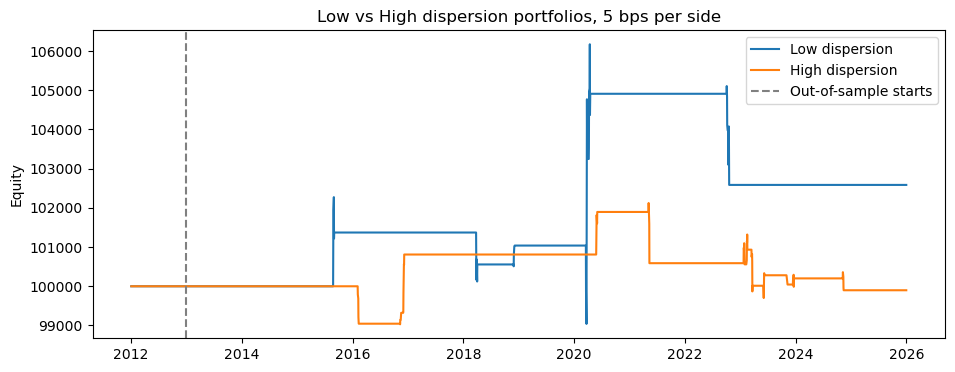

In [17]:
class Position:
    def __init__(self, signal, entry_time, lot_size, cost_rate):
        self.ticker = signal.ticker              # column of the ETF we buy
        self.peers = signal.peers                # columns of its peers
        self.group = signal.group                # Low or High dispersion
        self.peer_mean = signal.peer_mean        # peers' average return on the signal day
        self.dispersion = signal.dispersion      # scaled dispersion on the signal day
        self.signal_time = signal.time           # row of the signal close
        self.entry_time = entry_time             # row of the next open
        self.exit_time = entry_time + HOLD - 1   # row of the planned exit close
        self.entry_price = opens[entry_time, self.ticker]
        self.peer_entry_prices = opens[entry_time, self.peers]
        # Peer-relative move from the signal close to our entry open: catch-up we cannot capture.
        target_gap = self.entry_price / closes[self.signal_time, self.ticker] - 1
        peer_gap = (self.peer_entry_prices / closes[self.signal_time, self.peers]).mean() - 1
        self.gap_relative_return = target_gap - peer_gap
        self.lot_size = lot_size
        self.cost_rate = cost_rate
        self.entry_cost = self.value(self.entry_price) * cost_rate
        self.exit_price = None
        self.exit_cost = 0
        self.pnl = 0                             # net of costs, updated when closed
        self.relative_return = None              # target minus peers, updated when closed

    def value(self, price):
        return self.lot_size * price

    def close(self):
        self.exit_price = closes[self.exit_time, self.ticker]
        self.exit_cost = self.value(self.exit_price) * self.cost_rate
        self.pnl = self.lot_size * (self.exit_price - self.entry_price) - self.entry_cost - self.exit_cost
        target_return = self.exit_price / self.entry_price - 1
        peer_return = (closes[self.exit_time, self.peers] / self.peer_entry_prices).mean() - 1
        self.relative_return = target_return - peer_return  # positive = the target caught up

    def to_record(self):
        return {
            "ticker": tickers[self.ticker], "group": self.group,
            "signal_date": dates[self.signal_time], "entry_date": dates[self.entry_time],
            "exit_date": dates[self.exit_time], "peers": [tickers[p] for p in self.peers],
            "peer_mean": self.peer_mean, "dispersion": self.dispersion, "pnl": self.pnl,
            "net_return": self.pnl / self.value(self.entry_price),
            "relative_return": self.relative_return,
            "gap_relative_return": self.gap_relative_return,
        }


class Portfolio:
    def __init__(self, group, capital, cost_bps):
        self.group = group
        self.capital = capital
        self.cash = capital
        self.cost_rate = cost_bps / 10_000
        self.positions = {}       # open positions keyed by ETF column: O(1) "already held?" check
        self.closed = []
        self.skipped = 0
        self.equity_evolution = []
        self.exposure = []

    def equity(self, prices):
        return self.cash + sum(p.value(prices[t]) for t, p in self.positions.items())

    def open(self, signal, i):
        if signal.ticker in self.positions:  # one position per ETF
            self.skipped += 1
            return
        notional = POSITION_PCT * self.equity(opens[i])
        cost = notional * self.cost_rate
        if notional + cost > self.cash:      # no leverage
            self.skipped += 1
            return
        self.positions[signal.ticker] = Position(signal, i, notional / opens[i, signal.ticker], self.cost_rate)
        self.cash -= notional + cost

    def close_due(self, i):
        for t in list(self.positions):
            position = self.positions[t]
            if position.exit_time == i:
                position.close()
                self.cash += position.value(position.exit_price) - position.exit_cost
                self.closed.append(position)
                del self.positions[t]

    def mark_to_market(self, i):
        equity = self.equity(closes[i])
        self.equity_evolution.append(equity)
        self.exposure.append((equity - self.cash) / equity)


def run_backtest(signals, group, cost_bps):
    portfolio = Portfolio(group, CAPITAL, cost_bps)
    by_time = {time: rows for time, rows in signals[signals.group == group].groupby("time")}
    for i in test_days:
        # Morning: enter yesterday's signals at today's open, if the whole hold fits.
        if i - 1 in by_time and i + HOLD - 1 <= test_days[-1]:
            for signal in by_time[i - 1].itertuples():
                portfolio.open(signal, i)
        # Evening: exit trades due at today's close, then value the portfolio.
        portfolio.close_due(i)
        portfolio.mark_to_market(i)
    return portfolio


def trade_log(portfolio):
    return pd.DataFrame([p.to_record() for p in portfolio.closed])


def period_stats(portfolio, years):
    equity = pd.Series([portfolio.capital] + portfolio.equity_evolution)
    daily = (equity / equity.shift(1) - 1).iloc[1:]
    daily.index = dates[test_days]
    in_period = (daily.index.year >= years[0]) & (daily.index.year <= years[1])
    daily = daily[in_period]
    growth = (1 + daily).cumprod()
    trades = trade_log(portfolio)
    trades = trades[trades.signal_date.dt.year.between(*years)]
    return {
        "cumulative_return": growth.iloc[-1] - 1,
        "cagr": growth.iloc[-1] ** (252 / len(daily)) - 1,
        "sharpe": daily.mean() / daily.std() * 252 ** 0.5,
        "max_drawdown": (growth / growth.cummax().clip(lower=1) - 1).min(),
        "exposure": np.array(portfolio.exposure)[in_period].mean(),
        "trades": len(trades),
        "win_rate": (trades.pnl > 0).mean(),
        "mean_net_return": trades.net_return.mean(),
        "mean_relative_return": trades.relative_return.mean(),
        "mean_peer_move": trades.peer_mean.mean(),
    }


def bootstrap_low_minus_high(trades, n_resamples=1000, seed=0):
    """95% interval from resampling whole calendar months, keeping overlapping trades together."""
    blocks = [block for _, block in trades.groupby(trades.signal_date.dt.to_period("M"))]
    rng = np.random.default_rng(seed)
    differences = []
    for _ in range(n_resamples):
        sample = pd.concat([blocks[k] for k in rng.integers(0, len(blocks), len(blocks))])
        low = sample.loc[sample.group == "Low", "relative_return"].mean()
        high = sample.loc[sample.group == "High", "relative_return"].mean()
        differences.append(low - high)
    return np.nanpercentile(differences, [2.5, 97.5])


# 1. Backtests at three cost levels.
portfolios = {cost: {group: run_backtest(signals, group, cost) for group in ["Low", "High"]}
              for cost in [5, 10, 20]}

# 2. Headline results at 5 bps per side.
rows = []
for group, portfolio in portfolios[5].items():
    for period, years in [("In-sample 2012", IN_SAMPLE), ("Out-of-sample 2013-2025", OUT_OF_SAMPLE)]:
        rows.append({"group": group, "period": period, **period_stats(portfolio, years)})
results = pd.DataFrame(rows).set_index(["period", "group"]).sort_index()
print("All returns are decimals: 0.01 means 1%.")
print("Headline results (5 bps per side):")
display(results)

# 3. The hypothesis test: does Low catch up more than High, out of sample?
trades = pd.concat([trade_log(p) for p in portfolios[5].values()], ignore_index=True)
oos = trades[trades.signal_date.dt.year.between(*OUT_OF_SAMPLE)]
difference = (oos.loc[oos.group == "Low", "relative_return"].mean()
              - oos.loc[oos.group == "High", "relative_return"].mean())
low_ci, high_ci = bootstrap_low_minus_high(oos)
print(f"Out-of-sample Low minus High relative return: {difference:.2%} "
      f"(95% CI [{low_ci:.2%}, {high_ci:.2%}])")
print("Are the groups comparable? Average signal-day peer move and dispersion:")
display(oos.groupby("group")[["peer_mean", "dispersion"]].mean())
print("Catch-up missed overnight (signal close -> entry open) vs captured (entry open -> exit close):")
display(oos.groupby("group")[["gap_relative_return", "relative_return"]].mean())

# 4. Transaction-cost scenarios, out of sample.
cost_rows = []
for cost, pair in portfolios.items():
    for group, portfolio in pair.items():
        stats = period_stats(portfolio, OUT_OF_SAMPLE)
        cost_rows.append({"cost_bps_per_side": cost, "group": group,
                          "cumulative_return": stats["cumulative_return"],
                          "sharpe": stats["sharpe"], "max_drawdown": stats["max_drawdown"],
                          "skipped_signals": portfolio.skipped})
print("Out-of-sample results by transaction cost:")
display(pd.DataFrame(cost_rows))

fig, ax = plt.subplots(figsize=(11, 4))
for group, portfolio in portfolios[5].items():
    ax.plot(dates[test_days], portfolio.equity_evolution, label=f"{group} dispersion")
ax.axvline(pd.Timestamp(f"{OUT_OF_SAMPLE[0]}-01-01"), color="grey", linestyle="--", label="Out-of-sample starts")
ax.set_ylabel("Equity")
ax.set_title("Low vs High dispersion portfolios, 5 bps per side")
ax.legend()
plt.show()